# Single qubit Gates

An important feature of quantum circuits is that, between initializing the qubits and measuring them, the operations (gates) are always reversible!

These reversible gates can be represented as matrices, and as rotations around the Bloch sphere.

In [1]:
from qiskit import QuantumCircuit, assemble, Aer
from math import pi, sqrt
from qiskit.visualization import plot_bloch_multivector, plot_histogram
sim = Aer.get_backend('aer_simulator')

## Pauli Gates:
### The X-gate
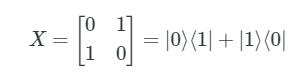

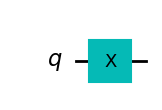

In [8]:
# Let's do an X-gate on a |0> qubit
qc = QuantumCircuit(1)
qc.x(0)
#qc.x(0)
qc.draw()

Let's see the result of the above circuit.  
**Note:** Here we use plot_bloch_multivector() which takes a qubit's statevector instead of the Bloch vector.

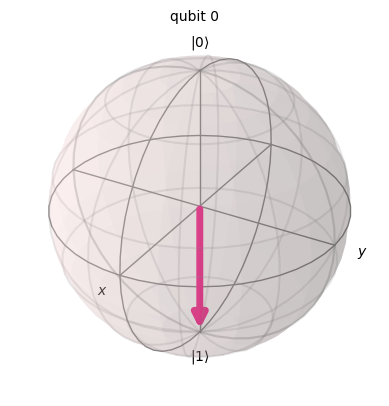

In [9]:
# Let's see the result
qc.save_statevector()
state = sim.run(qc).result().get_statevector()
plot_bloch_multivector(state)

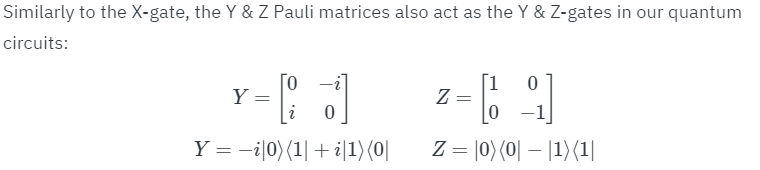

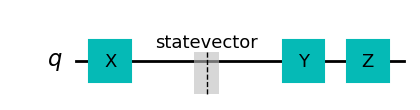

In [10]:
#implementation in Qiskit

qc.y(0) # Do Y-gate on qubit 0
qc.z(0) # Do Z-gate on qubit 0
qc.draw()

## Hadamard Gate

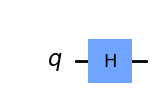

In [15]:
qc = QuantumCircuit(1)
qc.h(0)
qc.draw()

### Exercices:
* Show that applying the sequence of gates: HZH, to any qubit state is equivalent to applying an X-gate.  
* Find a combination of X, Z and H-gates that is equivalent to a Y-gate (ignoring global phase).

### How to measure in the x-basis
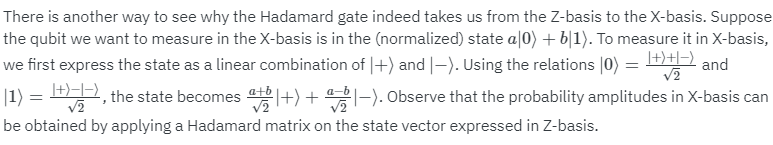


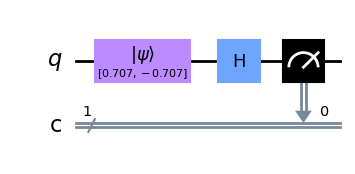

In [8]:
# Create the X-measurement function:
def x_measurement(qc, qubit, cbit):
    """Measure 'qubit' in the X-basis, and store the result in 'cbit'"""
    qc.h(qubit)
    qc.measure(qubit, cbit)
    return qc

initial_state = [1/sqrt(2), -1/sqrt(2)]
# Initialize our qubit and measure it
qc = QuantumCircuit(1,1)
qc.initialize(initial_state, 0)
x_measurement(qc, 0, 0)  # measure qubit 0 to classical bit 0
qc.draw()

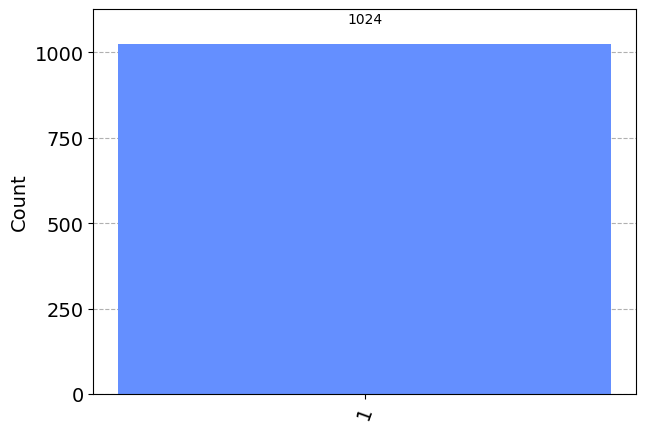

In [10]:
## Let's see the results of the measurement:
counts = sim.run(qc).result().get_counts()  # Do the simulation, returning the state vector
plot_histogram(counts)  # Display the output on measurement of state vector

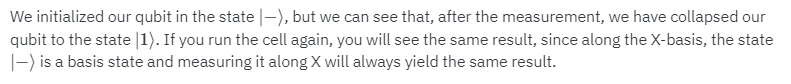

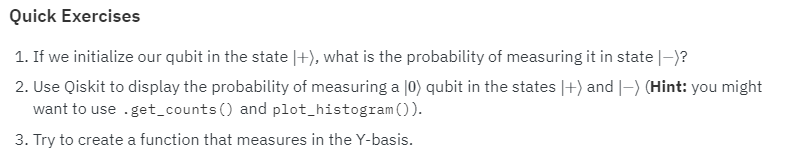

## P gate 
Rotation of $\phi$ around the Z-axis

In [11]:
# Run the code in this cell to see the widget
from qiskit_textbook.widgets import gate_demo
gate_demo(gates='pauli+h+p')

Image(value=b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHDR\x00\x00\x01\xe0\x00\x00\x01\xe0\x08\x06\x00\x00\x00}\xd4\xbe…

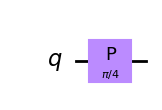

In [12]:
qc = QuantumCircuit(1)
qc.p(pi/4, 0)
qc.draw()

## S gate
This is the P gate with $\phi=\pi/2$

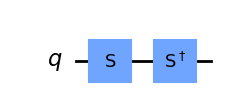

In [13]:
qc = QuantumCircuit(1)
qc.s(0)   # Apply S-gate to qubit 0
qc.sdg(0) # Apply Sdg-gate to qubit 0
qc.draw()

## The T-gate
This is the T gate with $\phi=\pi/4$

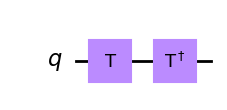

In [14]:
qc = QuantumCircuit(1)
qc.t(0)   # Apply T-gate to qubit 0
qc.tdg(0) # Apply Tdg-gate to qubit 0
qc.draw()

## The U-gate
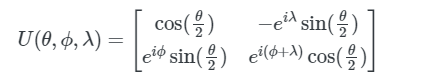

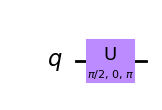

In [15]:
# Let's have U-gate transform a |0> to |+> state
qc = QuantumCircuit(1)
qc.u(pi/2, 0, pi, 0)
qc.draw()

# Perform operations with Operators and Statevectors

In [1]:
from qiskit.quantum_info import Statevector
from qiskit.quantum_info import Operator
from qiskit.visualization import plot_histogram, plot_bloch_vector
from numpy import sqrt
## define unitary operations using the Operator class
X = Operator([ [0,1],[1,0] ])
Y = Operator([ [0,-1.j],[1.j,0] ])
Z = Operator([ [1,0],[0,-1] ])
H = Operator([ [1/sqrt(2),1/sqrt(2)],[1/sqrt(2),-1/sqrt(2)] ])
S = Operator([ [1,0],[0,1.j] ])
T = Operator([ [1,0],[0,(1+1.j)/sqrt(2)] ])

v = Statevector([1,0])

v = v.evolve(H)
v = v.evolve(T)
v = v.evolve(H)
v = v.evolve(T)
v = v.evolve(Z)

v.draw('latex')

<IPython.core.display.Latex object>

In [2]:
v.measure()

('0',
 Statevector([0.92387953+0.38268343j, 0.        +0.j        ],
             dims=(2,)))

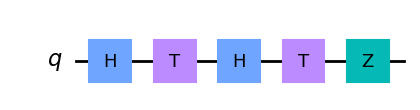

In [3]:
## Quantum circuits can be used to define composed unitary operation too
## this is using the quantum circuit class

from qiskit import QuantumCircuit

circuit = QuantumCircuit(1)

circuit.h(0)
circuit.t(0)
circuit.h(0)
circuit.t(0)
circuit.z(0)

circuit.draw()

The operations are applied sequentially, starting on the left and ending on the right in the figure. Let us first initialize a starting quantum state vector and then evolve that state according to the sequence of operations.

In [4]:
ket0 = Statevector([1,0])
v = ket0.evolve(circuit)
v.draw('latex')

<IPython.core.display.Latex object>

Finally, let's simulate the result of running this experiment (i.e., preparing the state , applying the sequence of operations represented by the circuit, and measuring) 4000 times.

In [5]:
statistics = v.sample_counts(4000)
plot_histogram(statistics)

Traceback (most recent call last):
  Cell In[5], line 2
    plot_histogram(statistics)
NameError: name 'plot_histogram' is not defined

Use %tb to get the full traceback.
